In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("data_khach_hang.csv")
df.head()

,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


In [6]:

print(df["Frequency"].skew().round(2))
print(df["MonetaryGBP"].skew().round(2))
print(df["TotalUnits"].skew().round(2))
print(df["AvgProductsPerInvoice"].skew().round(2))
print(df["RecencyDays"].skew().round(2))
print(df["ObservedTenureDays"].skew().round(2))
print(df["AvgOrderValueGBP"].skew().round(2))

5.3
9.59
14.3
3.29
0.57
-0.71
16.67


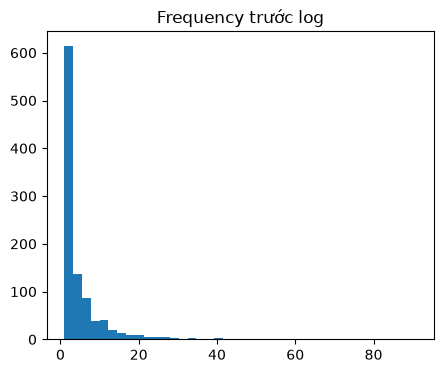

In [11]:
plt.figure(figsize=(5,4))
plt.hist(df["Frequency"], bins=40)
plt.title("Frequency trước log")
plt.show()

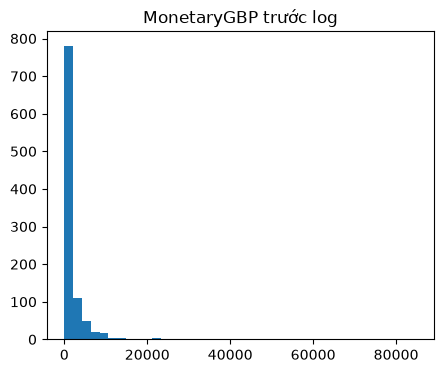

In [ ]:
plt.figure(figsize=(5,4))
plt.hist(df["MonetaryGBP"], bins=40)
plt.title("MonetaryGBP trước log")
plt.show()

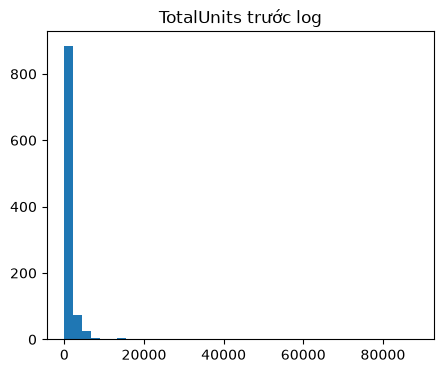

In [13]:
plt.figure(figsize=(5,4))
plt.hist(df["TotalUnits"], bins=40)
plt.title("TotalUnits trước log")
plt.show()

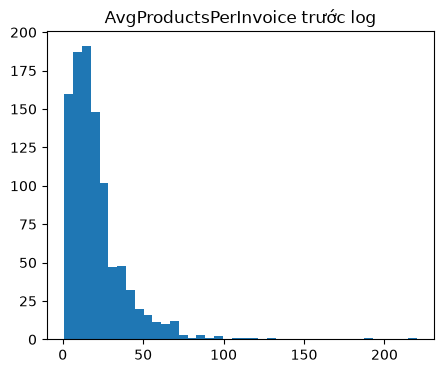

In [14]:
plt.figure(figsize=(5,4))
plt.hist(df["AvgProductsPerInvoice"], bins=40)
plt.title("AvgProductsPerInvoice trước log")
plt.show()

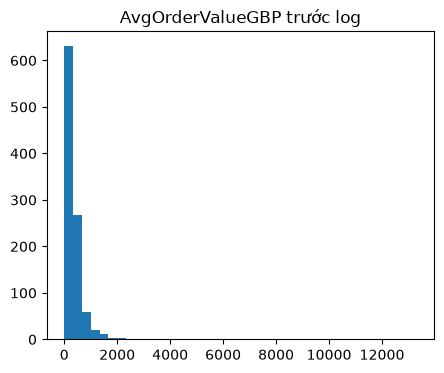

In [15]:
plt.figure(figsize=(5,4))
plt.hist(df["AvgOrderValueGBP"], bins=40)
plt.title("AvgOrderValueGBP trước log")
plt.show()

In [19]:
df2 =  df.drop(columns=['CustomerID', 'Chi_tieu_90_ngay_GBP','Mua_lai_90_ngay','Country','RegionGroup','Kenh_lien_he_mo_phong'])
df2.head()

,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,RecencyDays,ObservedTenureDays,AvgOrderValueGBP
0,1,1079.40,530,58.000000,132,132,1079.400000
1,3,1774.04,622,17.333333,50,450,591.346667
2,2,552.00,408,11.500000,9,142,276.000000
3,2,641.38,174,11.000000,191,191,320.690000
4,5,3018.07,2053,29.600000,174,524,603.614000


In [20]:
log_cols = ["Frequency", "MonetaryGBP", "TotalUnits", "AvgProductsPerInvoice", "AvgOrderValueGBP"]
df2_log = df2.copy()
df2_log[log_cols] = np.log1p(df2_log[log_cols])

In [22]:
print(df2_log["Frequency"].skew().round(2))
print(df2_log["MonetaryGBP"].skew().round(2))
print(df2_log["TotalUnits"].skew().round(2))
print(df2_log["AvgProductsPerInvoice"].skew().round(2))
print(df2_log["RecencyDays"].skew().round(2))
print(df2_log["ObservedTenureDays"].skew().round(2))
print(df2_log["AvgOrderValueGBP"].skew().round(2))

1.01
0.17
-0.21
-0.38
0.57
-0.71
-0.11


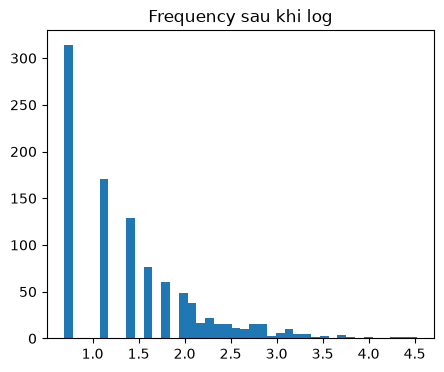

In [24]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["Frequency"], bins=40)
plt.title("Frequency sau khi log")
plt.show()

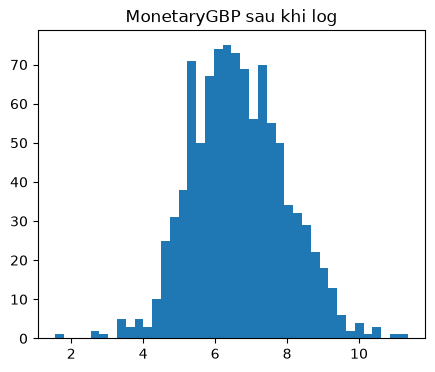

In [25]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["MonetaryGBP"], bins=40)
plt.title("MonetaryGBP sau khi log")
plt.show()

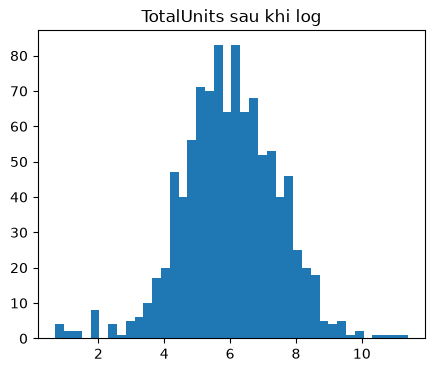

In [26]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["TotalUnits"], bins=40)
plt.title("TotalUnits sau khi log")
plt.show()

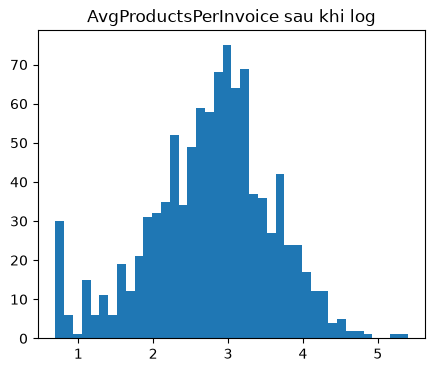

In [27]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["AvgProductsPerInvoice"], bins=40)
plt.title("AvgProductsPerInvoice sau khi log")
plt.show()

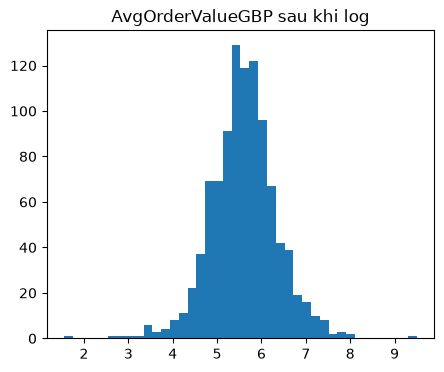

In [28]:
plt.figure(figsize=(5,4))
plt.hist(df2_log["AvgOrderValueGBP"], bins=40)
plt.title("AvgOrderValueGBP sau khi log")
plt.show()

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df2_log)

pca_full = PCA(random_state=42).fit(X_scaled)
evr = pca_full.explained_variance_ratio_     # phương sai từng thành phần
cum = np.cumsum(evr)                         # phương sai tích lũy
print(evr.round(3))
print(cum.round(3))

[0.521 0.191 0.168 0.079 0.025 0.016 0.   ]
[0.521 0.712 0.88  0.958 0.983 1.    1.   ]


In [31]:
TARGET = 0.85
n = int(np.argmax(cum >= TARGET) + 1)
print(f"==> Chọn {n} thành phần, giữ {cum[n-1]:.1%} phương sai")

# So sánh: chỉ chuẩn hóa vs. log1p + chuẩn hóa (số thành phần cho 85% / 90% / 95%)
def so_thanh_phan(data):
    Z = StandardScaler().fit_transform(data)
    c = np.cumsum(PCA(random_state=42).fit(Z).explained_variance_ratio_)
    return [int(np.argmax(c >= t) + 1) for t in (0.85, 0.90, 0.95)]

print("Chỉ StandardScaler    :", so_thanh_phan(df1))
print("log1p + StandardScaler:", so_thanh_phan(df2_log))

==> Chọn 3 thành phần, giữ 88.0% phương sai
Chỉ StandardScaler    : [4, 5, 6]
log1p + StandardScaler: [3, 4, 4]


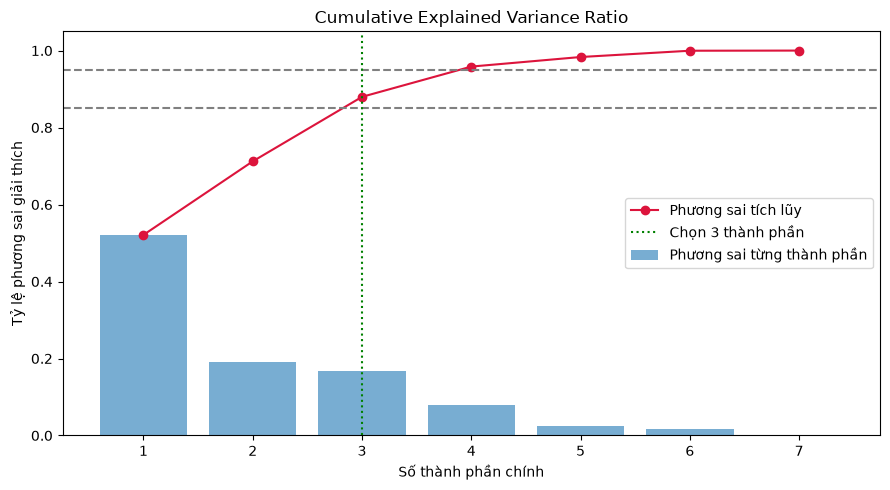

In [ ]:
x = np.arange(1, len(evr) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, evr, alpha=0.6, label="Phương sai từng thành phần")
ax.plot(x, cum, marker="o", color="crimson", label="Phương sai tích lũy")
ax.axhline(0.85, ls="--", color="gray")
ax.axhline(0.95, ls="--", color="gray")
ax.axvline(n, ls=":", color="green", label=f"Chọn {n} thành phần")
ax.set_xlabel("Số thành phần chính")
ax.set_ylabel("Tỷ lệ phương sai giải thích")
ax.set_title("Cumulative Explained Variance Ratio")
ax.legend(loc="center right")
plt.tight_layout()
plt.savefig("pca_variance.png", dpi=150)
plt.show()

In [33]:
pca = PCA(n_components=n, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pc_cols = [f"PC{i+1}" for i in range(n)]
df_pca = pd.DataFrame(X_pca, columns=pc_cols)
df_pca.insert(0, "CustomerID", df["CustomerID"].values)   # lấy từ df gốc

print("Phương sai giữ lại:", pca.explained_variance_ratio_.sum().round(3))
df_pca.head()

Phương sai giữ lại: 0.88


,CustomerID,PC1,PC2,PC3
0,12354,0.505565,-3.045908,0.194336
1,12358,1.222284,-0.376677,-0.016404
2,12363,-0.397573,-1.053059,-1.614249
3,12365,-0.850635,-0.763688,-0.536342
4,12370,2.096434,-0.112264,0.972179


In [34]:
print(len(df) == len(df2_log))
print((df.index == df2_log.index).all())

True
True


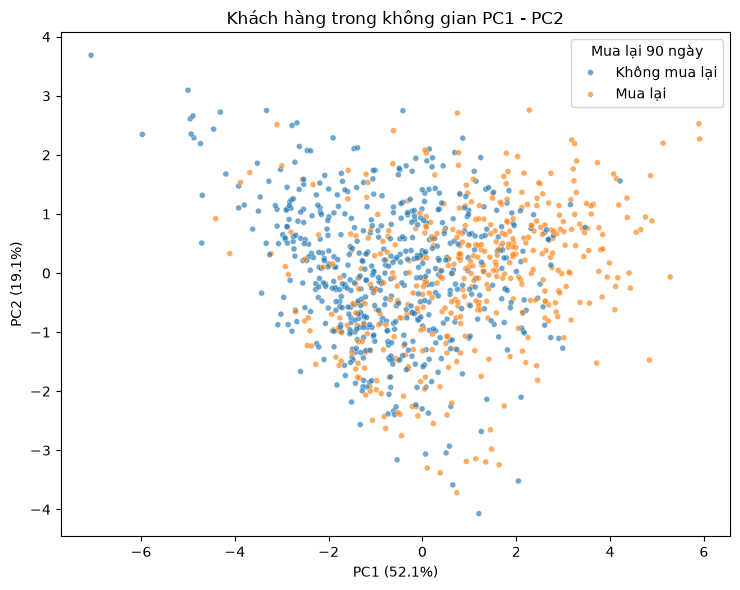

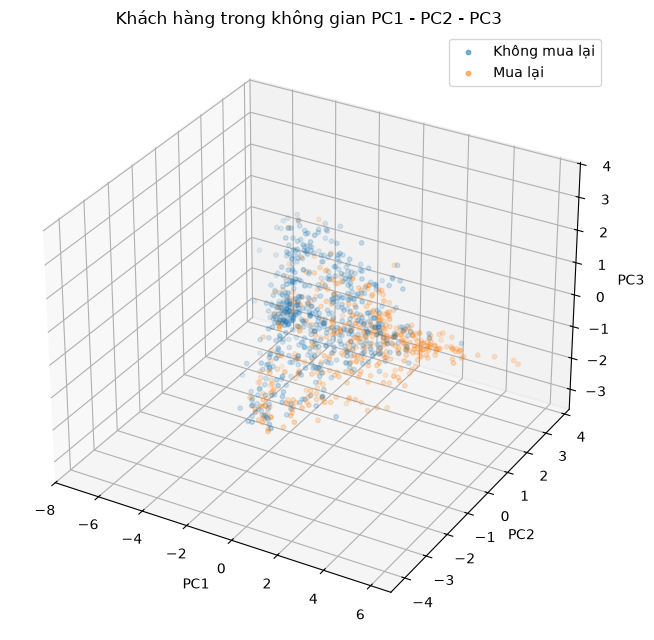

In [35]:
nhan = df["Mua_lai_90_ngay"].map({0: "Không mua lại", 1: "Mua lại"})

# --- 2D ---
plt.figure(figsize=(7.5, 6))
sns.scatterplot(x=df_pca["PC1"], y=df_pca["PC2"], hue=nhan, s=18, alpha=0.65)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Khách hàng trong không gian PC1 - PC2")
plt.legend(title="Mua lại 90 ngày")
plt.tight_layout()
plt.savefig("pca_scatter_2d.png", dpi=150)
plt.show()

# --- 3D (cần ít nhất 3 thành phần) ---
if n >= 3:
    fig = plt.figure(figsize=(8, 6.5))
    ax3 = fig.add_subplot(111, projection="3d")
    for gia_tri, mau in [("Không mua lại", "tab:blue"), ("Mua lại", "tab:orange")]:
        m = (nhan == gia_tri).values
        ax3.scatter(df_pca.loc[m, "PC1"], df_pca.loc[m, "PC2"], df_pca.loc[m, "PC3"],
                    s=10, alpha=0.55, color=mau, label=gia_tri)
    ax3.set_xlabel("PC1"); ax3.set_ylabel("PC2"); ax3.set_zlabel("PC3")
    ax3.set_title("Khách hàng trong không gian PC1 - PC2 - PC3")
    ax3.legend()
    plt.tight_layout()
    plt.savefig("pca_scatter_3d.png", dpi=150)
    plt.show()

                        PC1   PC2   PC3
Frequency              0.43  0.39 -0.20
MonetaryGBP            0.51  0.03 -0.00
TotalUnits             0.50 -0.00  0.03
AvgProductsPerInvoice  0.22 -0.55  0.34
RecencyDays           -0.29  0.13  0.72
ObservedTenureDays     0.23  0.57  0.51
AvgOrderValueGBP       0.35 -0.45  0.26


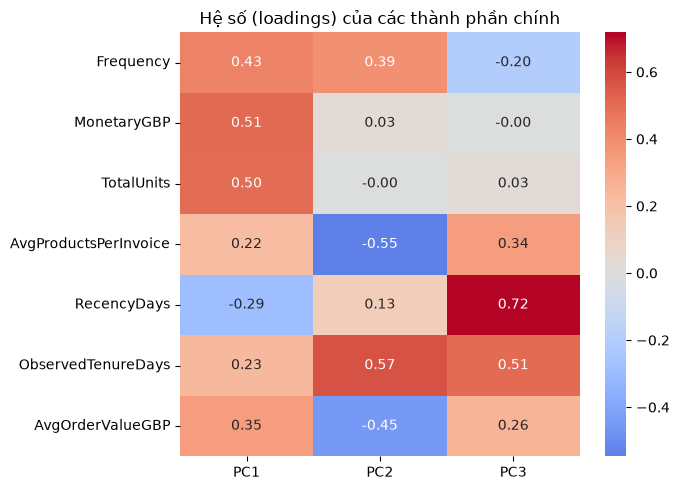

In [36]:
loadings = pd.DataFrame(pca.components_.T, index=df1.columns, columns=pc_cols)
print(loadings.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Hệ số (loadings) của các thành phần chính")
plt.tight_layout()
plt.savefig("pca_loadings.png", dpi=150)
plt.show()